In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import plotly as plotly



## Latency 1:1

In [2]:
# datos1 = pd.read_csv('receptor/datos1.csv')
# datos2 = pd.read_csv('receptor/datos2.csv')
# datos3 = pd.read_csv('receptor/datos3.csv')
# datos4 = pd.read_csv('receptor/datos4.csv')
# datos5 = pd.read_csv('receptor/datos5.csv')

df = pd.read_csv('swarm_metrics_1777900981.csv')

### Latency m:m

Text(0.5, 0.98, 'Temporal Evolution of Multi-Agent System Metrics')

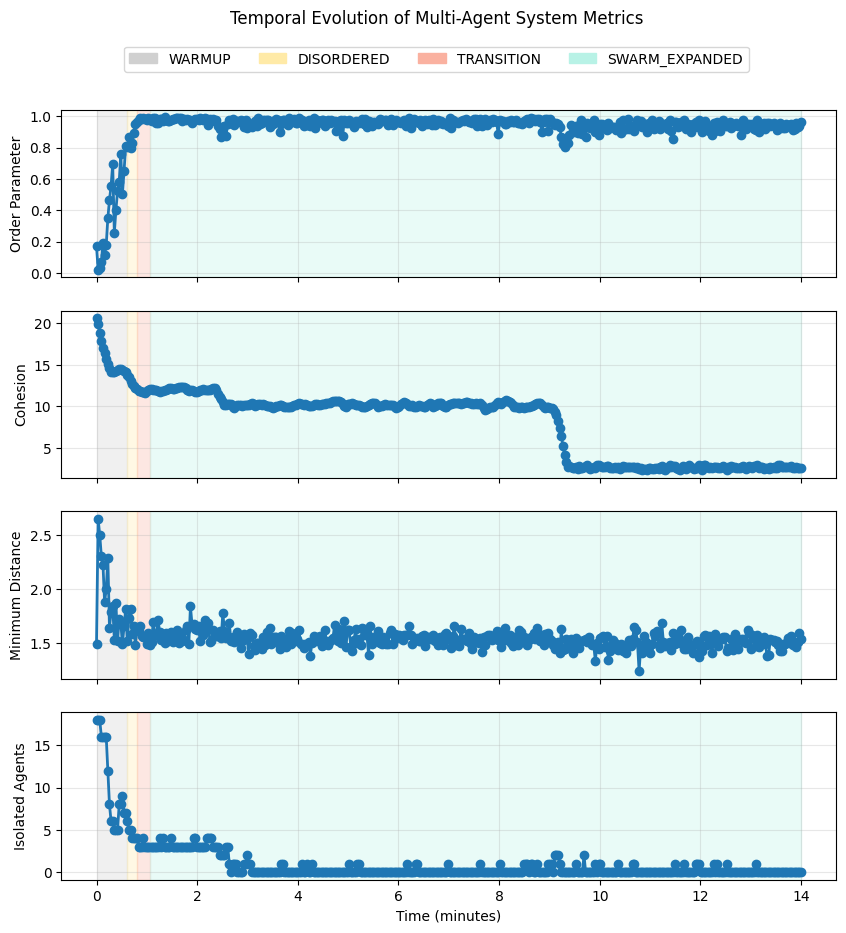

In [ ]:
# Tiempo total: 14 minutos
df["time"] = np.linspace(0, 14, len(df))

# =========================
# Colores por estado
# =========================

state_colors = {
    "WARMUP": "#d0d0d0",
    "DISORDERED": "#ffeaa7",
    "TRANSITION": "#fab1a0",
    "SWARM_EXPANDED": "#b8f2e6"
}

# =========================
# Detectar segmentos automáticamente
# =========================

segments = []

start_idx = 0
current_state = df.loc[0, "state"]

for i in range(1, len(df)):
    state = df.loc[i, "state"]

    if state != current_state:
        segments.append((
            current_state,
            df.loc[start_idx, "time"],
            df.loc[i, "time"]
        ))

        start_idx = i
        current_state = state

# Último segmento
segments.append((
    current_state,
    df.loc[start_idx, "time"],
    df.loc[len(df)-1, "time"]
))

# =========================
# Crear figura
# =========================

fig, axs = plt.subplots(
    4, 1,
    figsize=(10, 10),
    sharex=True
)

metrics = [
    ("order_param", "Order Parameter"),
    ("cohesion", "Cohesion"),
    ("min_distance", "Minimum Distance"),
    ("isolated_agents", "Isolated Agents")
]

# =========================
# Dibujar métricas
# =========================

for ax, (col, title) in zip(axs, metrics):

    # Fondo por estado
    for state, start, end in segments:
        ax.axvspan(
            start,
            end,
            color=state_colors.get(state, "#cccccc"),
            alpha=0.3
        )

    # Serie temporal
    ax.plot(
        df["time"],
        df[col],
        marker='o',
        linewidth=2
    )

    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)

# =========================
# Etiquetas de estado
# =========================

y_top = axs[0].get_ylim()[1] * 0.85

legend_patches = [
    mpatches.Patch(color=color, label=state)
    for state, color in state_colors.items()
]

fig.legend(
    handles=legend_patches,
    loc="upper center",
    ncol=len(state_colors),
    bbox_to_anchor=(0.5, 0.95)
)

axs[-1].set_xlabel("Time (minutes)")

plt.suptitle("Temporal Evolution of Multi-Agent System Metrics")

plt.savefig("../figures/MAS_evolution.pdf", format='pdf', bbox_inches='tight')